# Antimicrobial peptide (AMP) prediction: walkthrough
This notebook uses the `ampred` package in this repo. It loads the official AMP Scanner v2
train/eval/test splits, builds features, and shows the saved benchmark results.
Run `python -m ampred.benchmark` first (about 1-2 minutes on a laptop CPU).

In [1]:
import json
from ampred.data import download, load_split
from ampred.features import featurize, PHYSCHEM_NAMES
download("../data/raw")
train = load_split("train", "../data/raw")
test = load_split("test", "../data/raw")
print(len(train), "training peptides,", len(test), "test peptides")
print("example AMP:", train.seqs[0])

1424 training peptides, 1424 test peptides
example AMP: SLFSLIKAGAKFLGKNLLKQGACYAACKASKQC


## Simple features: what makes an AMP different?

In [2]:
import numpy as np
X = featurize(train.seqs, "physchem")
y = np.array(train.labels)
for i, name in enumerate(PHYSCHEM_NAMES):
    print(f"{name:20s} AMP mean={X[y==1,i].mean():7.3f}   non-AMP mean={X[y==0,i].mean():7.3f}")

length               AMP mean= 34.309   non-AMP mean= 34.545
net_charge           AMP mean=  3.452   non-AMP mean= -0.534
frac_cationic        AMP mean=  0.159   non-AMP mean=  0.117
frac_anionic         AMP mean=  0.042   non-AMP mean=  0.132
frac_hydrophobic     AMP mean=  0.397   non-AMP mean=  0.362
frac_aromatic        AMP mean=  0.088   non-AMP mean=  0.083
mean_hydropathy      AMP mean=  0.130   non-AMP mean= -0.372
hydrophobic_moment   AMP mean=  0.846   non-AMP mean=  0.577


## Benchmark results on the untouched test set

In [3]:
res = json.load(open("../results/metrics.json"))
for name, m in sorted(res["models"].items(), key=lambda kv: -kv[1]["auc"]):
    ci = m.get("auc_95ci")
    ci_s = f"[{ci[0]:.3f}, {ci[1]:.3f}]" if ci else ""
    print(f"{name:34s} AUC={m['auc']:.3f} {ci_s:16s} MCC={m['mcc']:.3f} ACC={m['accuracy']:.3f}")

ensemble[esm2+rf]                  AUC=0.977 [0.970, 0.984]   MCC=0.857 ACC=0.928
logreg[esm2_8M]                    AUC=0.975 [0.968, 0.983]   MCC=0.842 ACC=0.920
random_forest[aac+dpc+physchem]    AUC=0.963 [0.954, 0.971]   MCC=0.794 ACC=0.897
logreg[aac+dpc+physchem]           AUC=0.945 [0.933, 0.957]   MCC=0.770 ACC=0.885
logreg[aac+physchem]               AUC=0.944 [0.932, 0.956]   MCC=0.772 ACC=0.886
logreg[aac]                        AUC=0.934 [0.920, 0.947]   MCC=0.757 ACC=0.879
nearest_neighbour[3-mer]           AUC=0.887 [0.867, 0.904]   MCC=0.480 ACC=0.724
logreg[length]                     AUC=0.514 [0.484, 0.545]   MCC=0.000 ACC=0.500
majority_class                     AUC=0.500                  MCC=0.000 ACC=0.500


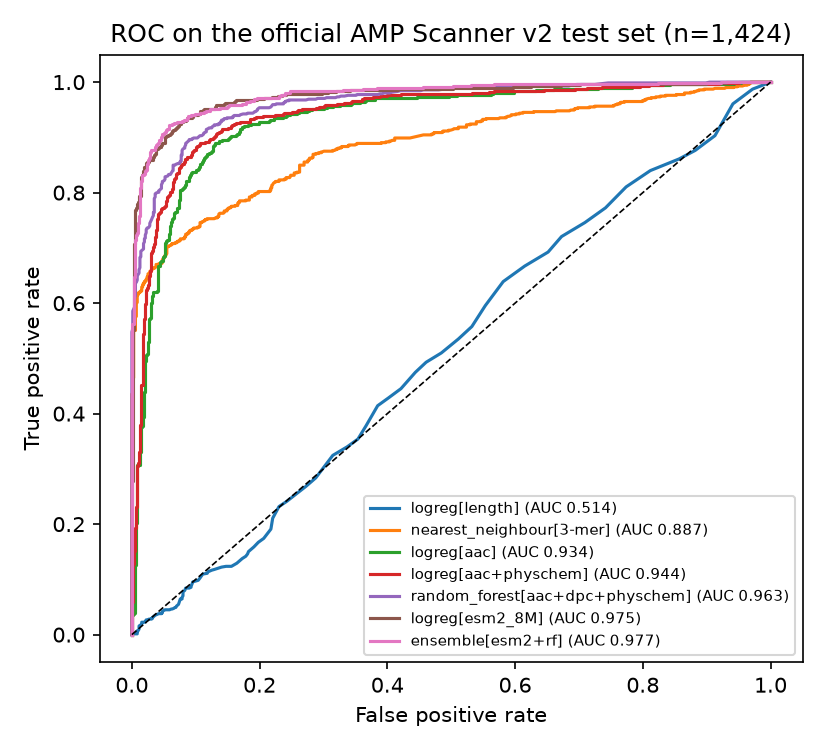

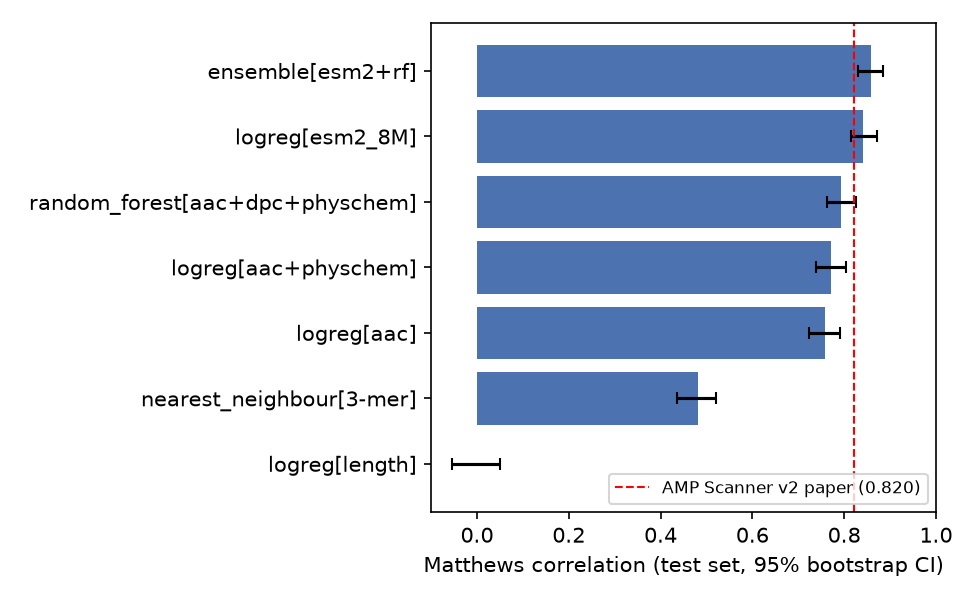

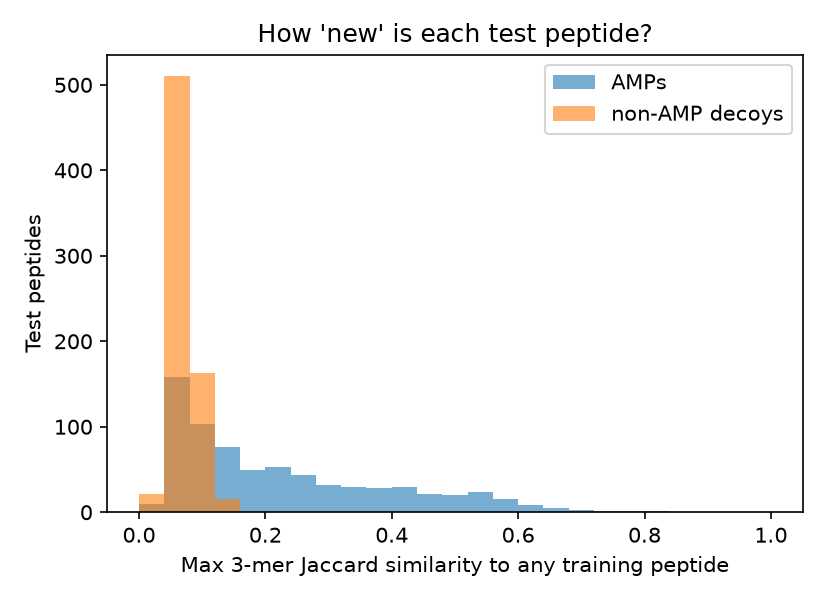

In [4]:
from IPython.display import Image, display
for f in ["roc_curves", "mcc_comparison", "test_similarity"]:
    display(Image(f"../figures/{f}.png"))

## Does the model only work on peptides it has 'seen'?
Accuracy is split by how similar each test peptide is to its closest training peptide.

In [5]:
for b, e in res["homology_bins_auc"].items():
    print(b, {k: (round(v, 3) if isinstance(v, float) else v) for k, v in e.items()})

0.0-0.2 {'n': 1108, 'frac_amp': 0.358, 'logreg[length]': 0.548, 'logreg[aac]': 0.916, 'logreg[aac+physchem]': 0.929, 'logreg[aac+dpc+physchem]': 0.924, 'logreg[esm2_8M]': 0.965, 'random_forest[aac+dpc+physchem]': 0.942, 'nearest_neighbour[3-mer]': 0.799, 'ensemble[esm2+rf]': 0.965}
0.2-0.4 {'n': 186, 'frac_amp': 0.995, 'logreg[length]': 0.768, 'logreg[aac]': 0.849, 'logreg[aac+physchem]': 0.951, 'logreg[aac+dpc+physchem]': 0.968, 'logreg[esm2_8M]': 0.957, 'random_forest[aac+dpc+physchem]': 0.984, 'nearest_neighbour[3-mer]': 0.943, 'ensemble[esm2+rf]': 0.984}
0.4-1.0 {'n': 130, 'frac_amp': 1.0}
